# Praktikum 1
HDBSCAN (Hierarchical Density-Based Spatial Clustering of Applications with Noise)

### Pengantar Praktikum
Pada praktikum ini kita akan mempelajari algoritma **HDBSCAN** sebagai salah satu metode clustering berbasis densitas yang lebih robust dibandingkan DBSCAN. Melalui pendekatan hierarki, HDBSCAN mampu mengatasi keterbatasan parameter `eps` yang sensitif pada DBSCAN serta dapat menyesuaikan diri dengan data yang memiliki kepadatan berbeda.

### Persiapan Lingkungan
Jalankan kode berikut untuk menyiapkan library yang diperlukan.

In [1]:
# Instalasi pustaka hdbscan (tidak tersedia default di sklearn)
!pip install -q hdbscan

In [2]:
# Import modul
import matplotlib.pyplot as plt
import numpy as np

from sklearn.cluster import DBSCAN
from sklearn.datasets import make_blobs
import hdbscan

### Langkah 2: Definisi Fungsi Visualisasi
Jalankan fungsi ini agar kita bisa mem-plot hasil clustering dengan warna berbeda.

In [3]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}

    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]  # warna hitam untuk noise
        class_index = (labels == k).nonzero()[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

### Langkah 3: Membuat Dataset Sintetis
Dataset terdiri dari 3 buah cluster Gaussian.

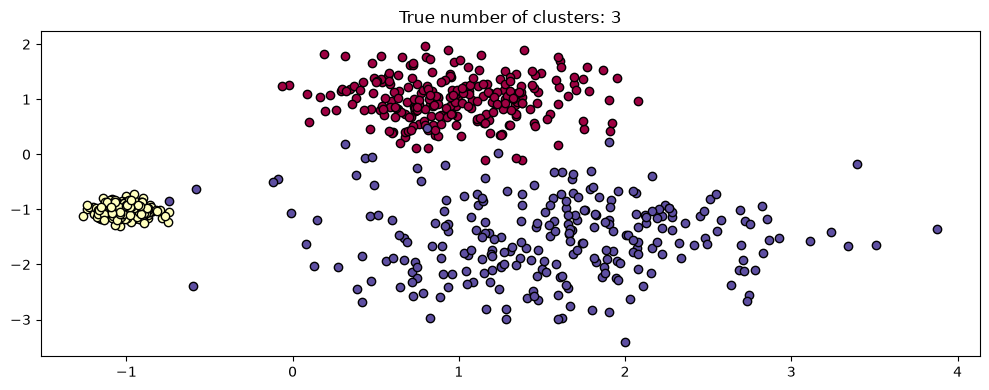

In [4]:
centers = [[1, 1], [-1, -1], [1.5, -1.5]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.4, 0.1, 0.75], random_state=0
)

plot(X, labels=labels_true, ground_truth=True)
plt.show()

### Langkah 4: Uji *Scale Invariance* pada DBSCAN
Jalankan DBSCAN dengan `eps=0.3` pada dataset yang di-*scale*.

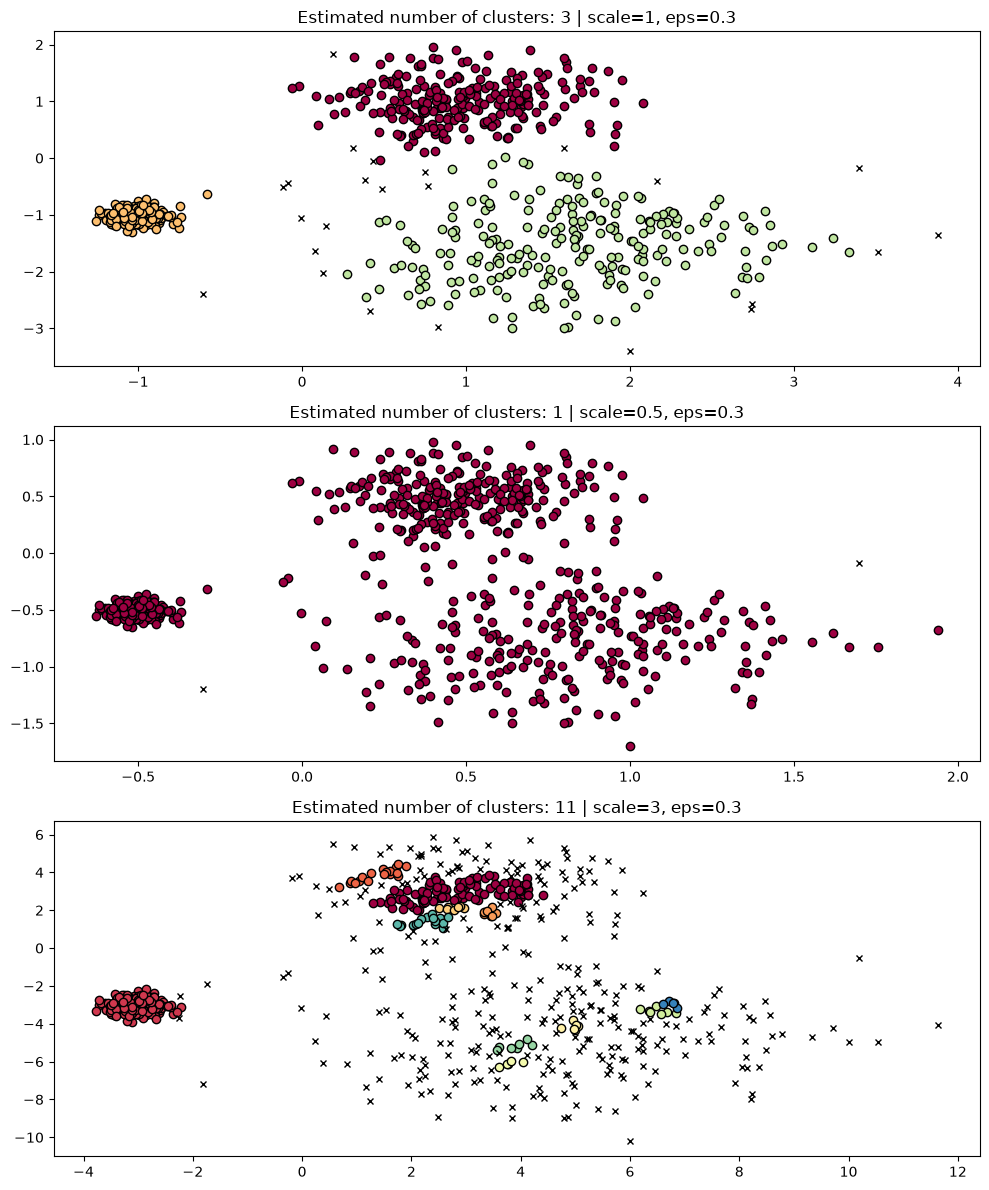

In [5]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
dbs = DBSCAN(eps=0.3)
for idx, scale in enumerate([1, 0.5, 3]):
    dbs.fit(X * scale)
    plot(X * scale, dbs.labels_, parameters={"scale": scale, "eps": 0.3}, ax=axes[idx])
plt.show()

Perbaiki dengan mengubah `eps` sesuai skala:

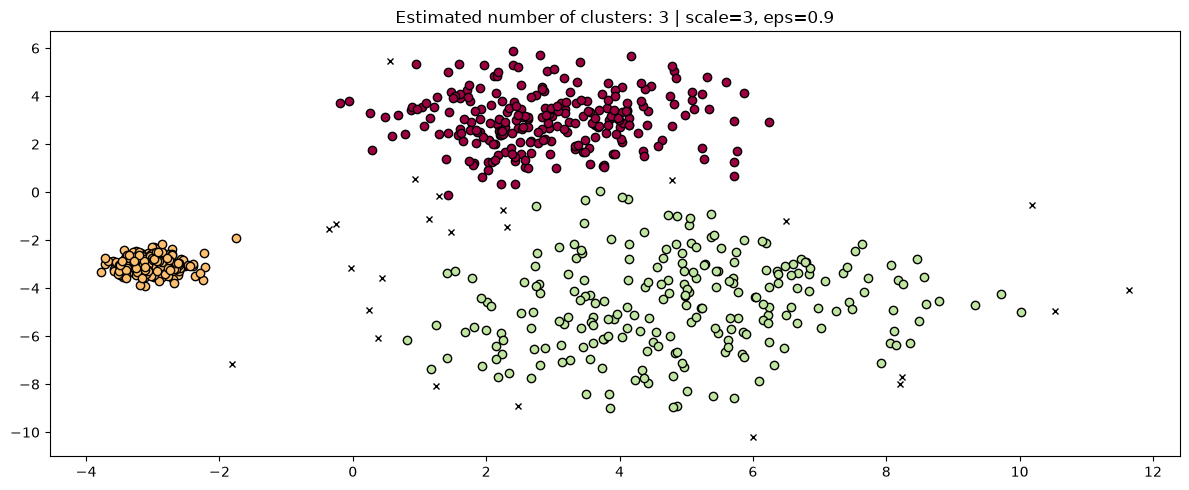

In [6]:
fig, axis = plt.subplots(1, 1, figsize=(12, 5))
dbs = DBSCAN(eps=0.9).fit(3 * X)
plot(3 * X, dbs.labels_, parameters={"scale": 3, "eps": 0.9}, ax=axis)
plt.show()

### Langkah 5: Bandingkan dengan HDBSCAN (lebih robust)
Jalankan HDBSCAN pada dataset berskala berbeda.

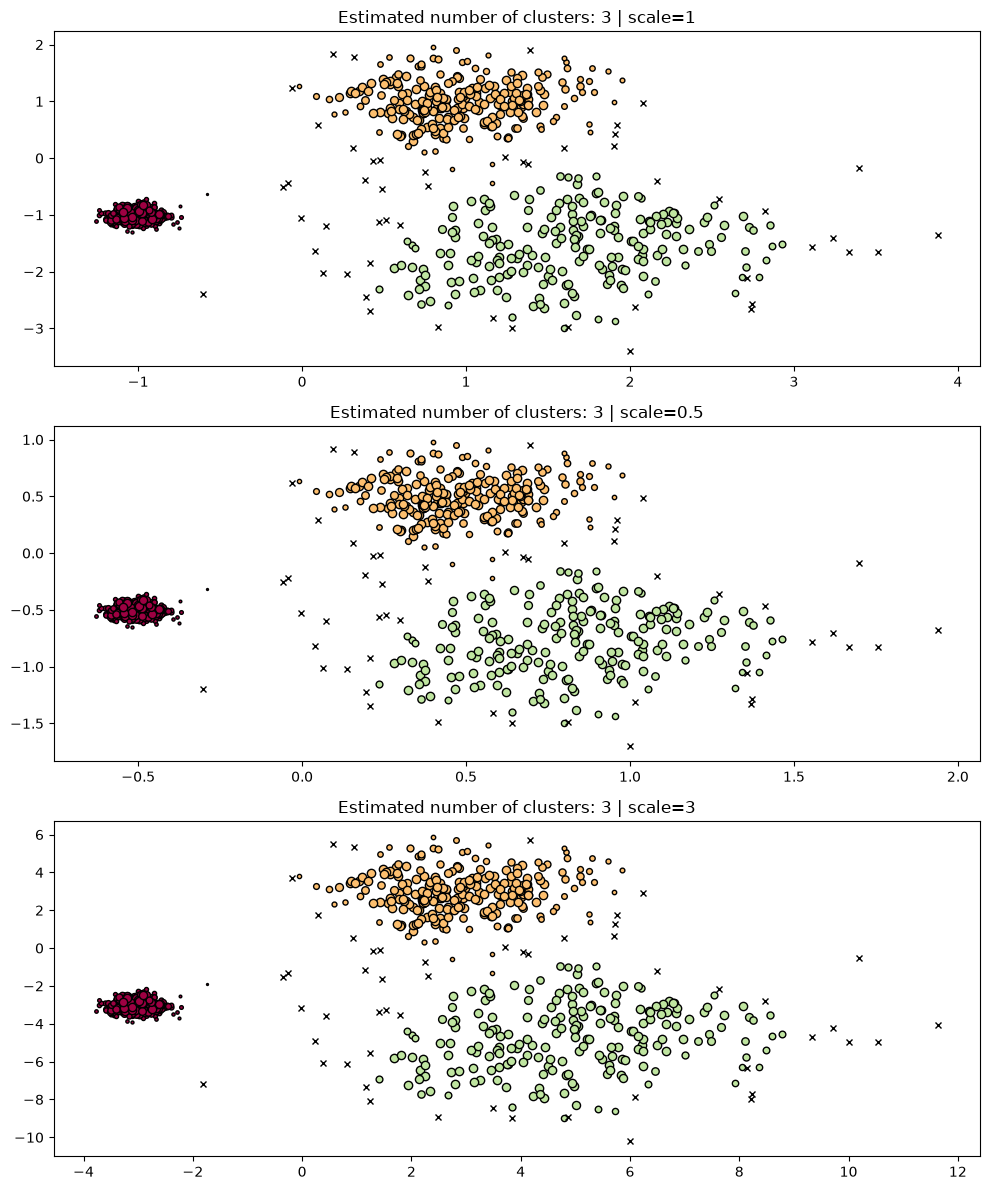

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
hdb = hdbscan.HDBSCAN()
for idx, scale in enumerate([1, 0.5, 3]):
    hdb.fit(X * scale)
    plot(X * scale, hdb.labels_, hdb.probabilities_, ax=axes[idx], parameters={"scale": scale})
plt.show()

> **Catatan:** Hasil HDBSCAN relatif stabil terhadap perubahan skala, berbeda dengan DBSCAN yang hasilnya berubah drastis ketika `eps` tidak disesuaikan dengan skala data.

### Langkah 6: Multi-Scale Clustering
Buat dataset baru dengan kepadatan berbeda.

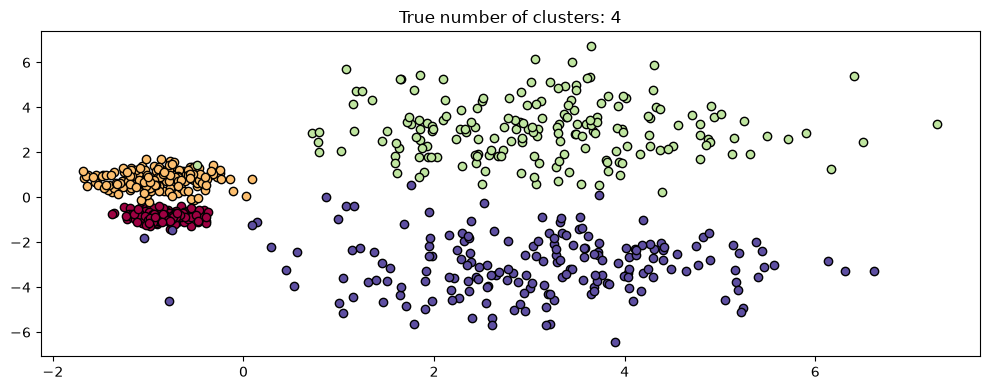

In [8]:
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(
    n_samples=750, centers=centers, cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0
)
plot(X, labels=labels_true, ground_truth=True)
plt.show()

Bandingkan DBSCAN dengan `eps` berbeda:

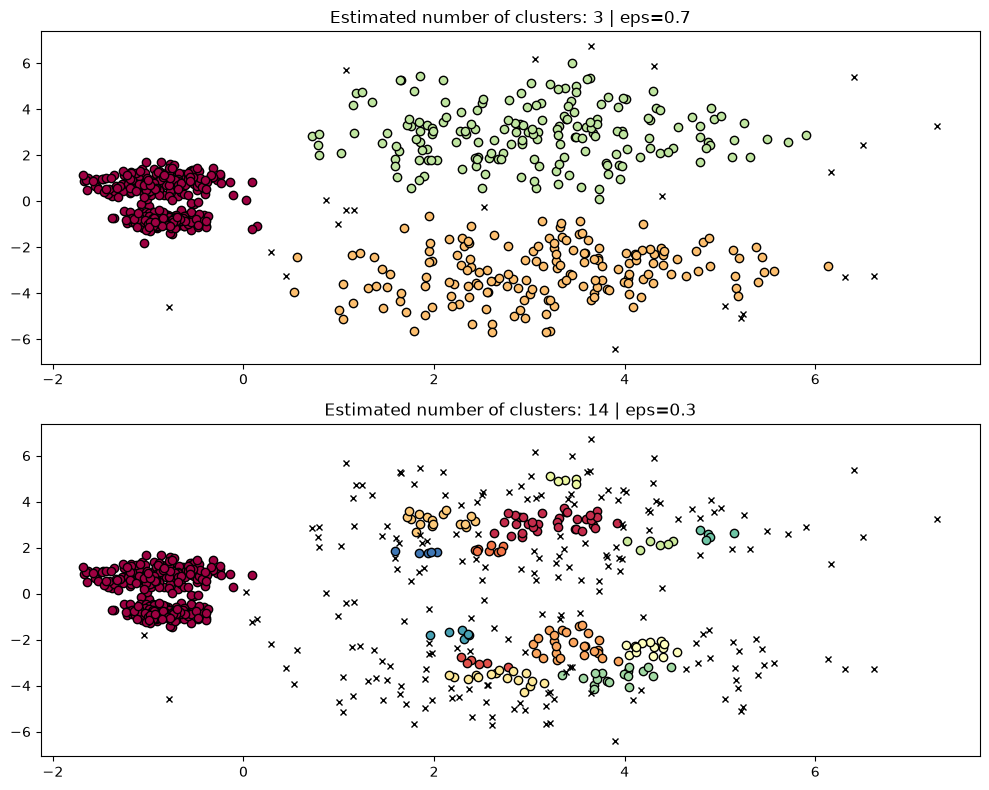

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(10, 8))
params = {"eps": 0.7}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[0])

params = {"eps": 0.3}
dbs = DBSCAN(**params).fit(X)
plot(X, dbs.labels_, parameters=params, ax=axes[1])
plt.show()

Jalankan HDBSCAN:

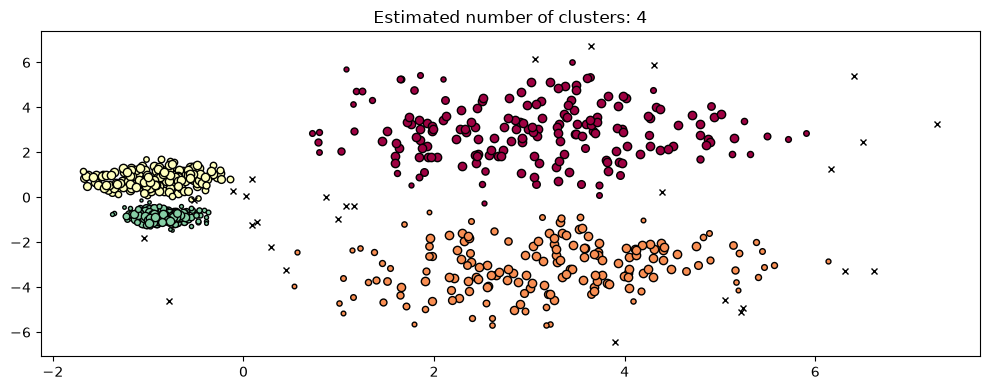

In [10]:
hdb = hdbscan.HDBSCAN().fit(X)
plot(X, hdb.labels_, hdb.probabilities_)
plt.show()

> **Interpretasi:** DBSCAN dengan satu nilai `eps` global sulit menangani dataset dengan kepadatan bervariasi. HDBSCAN berhasil menemukan keempat klaster sekaligus karena memilih klaster berdasarkan *stability* pada berbagai tingkat kepadatan.